# 01 – Exploratory data analysis

This notebook looks at the heart disease data before any modelling. The goals are:

1. Check data quality: duplicates, missing values, and whether the labels mean what we think.
2. Understand what each feature measures.
3. See which features differ between patients with and without heart disease.

The cleaning decisions made here are implemented in `src/data.py`, so the modelling code uses exactly the same data.

In [1]:
import sys
sys.path.append("..")  # so we can import from src/

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split

from src.data import load_raw, load_clean, FEATURES, NUMERIC_FEATURES

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Colours used in every plot
NO_DISEASE = "#2a78d6"   # blue
DISEASE = "#eb6834"      # orange
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "axes.axisbelow": True,
})

## 1. Data quality

### 1.1 Duplicates

In [2]:
raw = load_raw()
print("Shape of raw file:", raw.shape)
print("Missing values (NaN):", raw.isnull().sum().sum())
print("Exact duplicate rows:", raw.duplicated().sum())
print("Unique rows:", len(raw.drop_duplicates()))

Shape of raw file: (1025, 14)
Missing values (NaN): 0
Exact duplicate rows: 723
Unique rows: 302


In [3]:
# How many times does each unique patient appear?
copies = raw.groupby(list(raw.columns)).size()
copies.value_counts().sort_index().rename_axis("times a row appears").to_frame("number of patients")

,number of patients
times a row appears,
3,187
4,114
8,1


Only 302 of the 1,025 rows are unique. Most patients appear 3 or 4 times. The original UCI Cleveland data has 303 patients, and one of them is an exact duplicate there too, so 302 is the real number of distinct patients.

### 1.2 How much did the duplicates affect the old result?

The first version of this project used an 80/20 split on the raw file (`random_state=20`) and reported 92.2% test accuracy. Below I count how many test rows also appear in the training set in that split.

In [4]:
X_raw = raw.drop(columns="target")
X_tr, X_te = train_test_split(X_raw, test_size=0.2, random_state=20)

train_rows = set(map(tuple, X_tr.values))
seen = [tuple(row) in train_rows for row in X_te.values]
print(f"Test rows: {len(X_te)}")
print(f"Test rows that also appear in the training set: {sum(seen)}")
print(f"Test rows that are truly new: {len(X_te) - sum(seen)}")

Test rows: 205
Test rows that also appear in the training set: 199
Test rows that are truly new: 6


199 of the 205 test rows were copies of training rows. So the old 92.2% mostly measured whether the model could recognise patients it had already seen, not whether it works on new patients. This is data leakage. The fix is to drop duplicates **before** any split, which `load_clean()` does.

### 1.3 Is the target coded the right way round?

The Kaggle page says `target = 1` means heart disease. But the averages below look the wrong way round for that.

In [5]:
unique = raw.drop_duplicates()
unique.groupby("target")[["age", "thalach", "oldpeak", "exang", "ca"]].mean().round(2)

,age,thalach,oldpeak,exang,ca
target,,,,,
0,56.60,139.10,1.59,0.55,1.17
1,52.59,158.38,0.59,0.14,0.34


The `target = 1` group is younger, reaches a **higher** maximum heart rate (`thalach`), has **less** ST depression (`oldpeak`), **less** exercise-induced chest pain (`exang`) and **fewer** blocked vessels (`ca`). In the medical literature these are all signs of a *healthier* heart. Also, the original UCI data has 164 patients without disease, which is exactly the size of the `target = 1` group here.

I checked this properly by matching every one of the 302 unique Kaggle rows to its row in the original UCI Cleveland file (`processed.cleveland.data`, matched on age, blood pressure, cholesterol, max heart rate, oldpeak and fasting blood sugar). All 302 rows matched, and **in every row the Kaggle label is the opposite of the UCI label**. Others have reported the same issue (for example Tyler Burleigh's blog post from March 2020).

**Decision:** `load_clean()` flips the label, so in the rest of this project **1 = heart disease** and 0 = no heart disease. This matters for recall: we want recall of the *disease* class.

The cell below repeats the check. It only runs if you download `processed.cleveland.data` from the UCI repository (https://archive.ics.uci.edu/dataset/45/heart+disease) and put it in `data/`.

In [6]:
uci_path = Path("../data/processed.cleveland.data")

if uci_path.exists():
    uci = pd.read_csv(uci_path, header=None, names=FEATURES + ["num"], na_values="?")
    uci["uci_disease"] = (uci["num"] > 0).astype(int)  # num 1-4 means disease

    key = ["age", "trestbps", "chol", "thalach", "oldpeak", "fbs"]
    for col in key:
        uci[col] = uci[col].astype(float)
    kaggle = unique.copy()
    for col in key:
        kaggle[col] = kaggle[col].astype(float)

    matched = kaggle.merge(uci[key + ["uci_disease"]], on=key)
    print("Kaggle rows matched to UCI rows:", len(matched), "of", len(kaggle))
    display(pd.crosstab(matched["target"], matched["uci_disease"],
                        rownames=["Kaggle target"], colnames=["UCI disease"]))
else:
    print("processed.cleveland.data not found in data/ - skipping this check.")

processed.cleveland.data not found in data/ - skipping this check.


### 1.4 Missing values hidden as codes

There are no NaN values in the file, but two features have a value that is not in the dataset documentation:

In [7]:
print("ca  :", unique["ca"].value_counts().sort_index().to_dict())
print("thal:", unique["thal"].value_counts().sort_index().to_dict())

ca  : {0: 175, 1: 65, 2: 38, 3: 20, 4: 4}
thal: {0: 2, 1: 18, 2: 165, 3: 117}


`ca` (number of blocked major vessels) should be 0–3, but 4 patients have `ca = 4`. `thal` should be 1–3, but 2 patients have `thal = 0`. In the original UCI file exactly these patients have "?" (missing) for these columns. So `ca = 4` and `thal = 0` are missing values, not real categories. `load_clean()` turns them back into NaN. They are filled in later inside the model pipeline (with the most common value from the training folds), so no information from the test fold is used.

## 2. What each feature means

The Kaggle file uses different number codes from the original UCI documentation. The codes below were worked out by matching each Kaggle row to its UCI row (section 1.3), so they are checked against the data, not guessed.

| Feature | Meaning | Values in this file |
|---|---|---|
| `age` | Age | years (29–77) |
| `sex` | Sex | 1 = male, 0 = female |
| `cp` | Chest pain type | 0 = asymptomatic, 1 = atypical angina, 2 = non-anginal pain, 3 = typical angina |
| `trestbps` | Resting blood pressure | mm Hg (94–200) |
| `chol` | Serum cholesterol | mg/dl (126–564) |
| `fbs` | Fasting blood sugar > 120 mg/dl | 1 = yes, 0 = no |
| `restecg` | Resting ECG result | 0 = left ventricular hypertrophy, 1 = normal, 2 = ST-T wave abnormality |
| `thalach` | Maximum heart rate during the exercise test | beats per minute (71–202) |
| `exang` | Chest pain (angina) caused by exercise | 1 = yes, 0 = no |
| `oldpeak` | ST depression on the ECG during exercise, compared with rest | mm (0–6.2) |
| `slope` | Slope of the ST segment at peak exercise | 0 = downsloping, 1 = flat, 2 = upsloping |
| `ca` | Number of major vessels coloured by fluoroscopy | 0–3 (4 = missing) |
| `thal` | Thallium stress test result | 1 = fixed defect, 2 = normal, 3 = reversible defect (0 = missing) |
| `target` | Diagnosis from angiography | in the raw file 1 = **no** disease; flipped in `load_clean()` |

Feature types matter for modelling:
- **Numeric:** `age`, `trestbps`, `chol`, `thalach`, `oldpeak`, and `ca` (a count, so the order means something).
- **Binary:** `sex`, `fbs`, `exang`.
- **Categorical without order:** `cp`, `restecg`, `slope`, `thal`. Their numbers are just labels (e.g. `cp = 2` is not "twice" `cp = 1`), so they will be one-hot encoded for linear models and SVM.

## 3. Clean data and class balance

From here on we use the cleaned data from `load_clean()`.

In [8]:
X, y = load_clean(verbose=True)
df = X.assign(disease=y)

balance = y.value_counts().sort_index().to_frame("patients")
balance["share"] = (balance["patients"] / len(y)).round(3)
balance.index = ["no disease (0)", "disease (1)"]
balance

Rows before: 1025
Duplicates removed: 723
Rows after: 302
Missing values: ca = 4, thal = 2


,patients,share
no disease (0),164,0.543
disease (1),138,0.457


138 patients (45.7%) have heart disease and 164 (54.3%) do not. The classes are close to balanced, so accuracy is not misleading on its own, but we will still report recall, precision, F1 and ROC-AUC. We will also use **stratified** cross-validation so every fold keeps roughly this 46/54 ratio.

## 4. Numeric features

Histograms of each numeric feature, split by diagnosis.

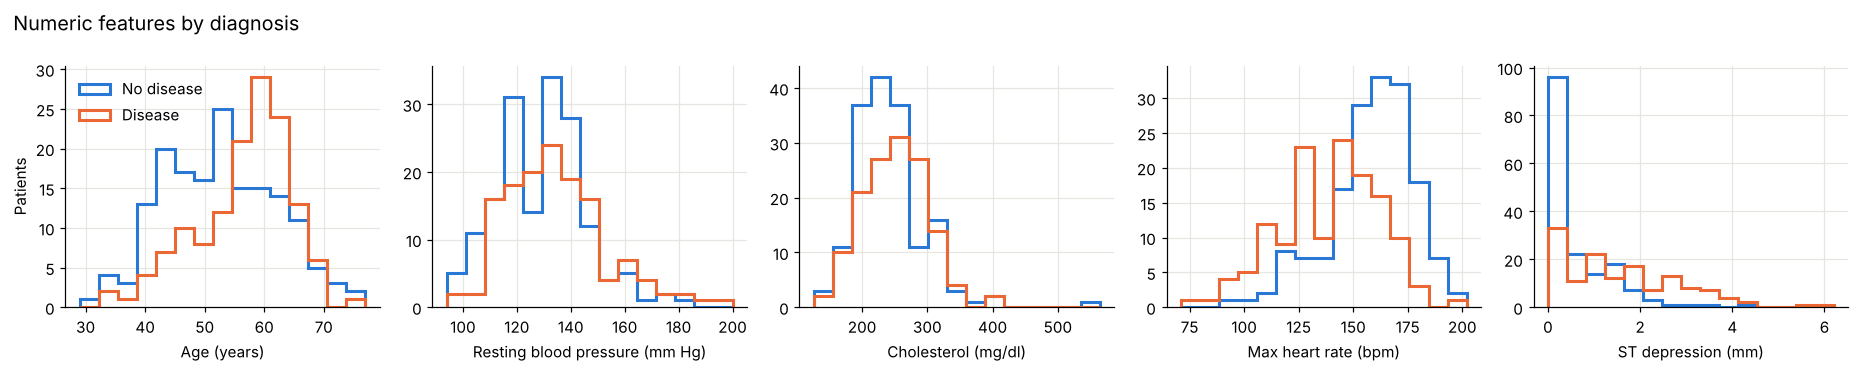

In [9]:
cont = ["age", "trestbps", "chol", "thalach", "oldpeak"]
labels = {"age": "Age (years)", "trestbps": "Resting blood pressure (mm Hg)",
          "chol": "Cholesterol (mg/dl)", "thalach": "Max heart rate (bpm)",
          "oldpeak": "ST depression (mm)"}

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, col in zip(axes, cont):
    bins = np.histogram_bin_edges(df[col], bins=15)
    ax.hist(df.loc[df.disease == 0, col], bins=bins, histtype="step", linewidth=2,
            color=NO_DISEASE, label="No disease")
    ax.hist(df.loc[df.disease == 1, col], bins=bins, histtype="step", linewidth=2,
            color=DISEASE, label="Disease")
    ax.set_xlabel(labels[col])
axes[0].set_ylabel("Patients")
axes[0].legend(frameon=False)
fig.suptitle("Numeric features by diagnosis", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "numeric_by_diagnosis.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Median of each numeric feature in each group
df.groupby("disease")[cont + ["ca"]].median().rename(index={0: "no disease", 1: "disease"})

,age,trestbps,chol,thalach,oldpeak,ca
disease,,,,,,
no disease,52.0,130.0,234.5,161.0,0.2,0.0
disease,58.0,130.0,249.0,142.0,1.4,1.0


What the plots show:
- **`thalach` (max heart rate)** separates the groups best: patients with disease usually reach a lower maximum heart rate.
- **`oldpeak`** is mostly 0 for patients without disease and higher for patients with disease.
- **`age`**: patients with disease are a few years older on average, but the groups overlap a lot.
- **`trestbps` and `chol`** overlap almost completely, so on their own they say little in this dataset.
- There are some extreme values (cholesterol 564, blood pressure 200, oldpeak 6.2). They are possible clinical values, not obvious errors, so I keep them.

## 5. Categorical and binary features

For each category, the bar shows the share of patients in it who have heart disease. The dashed line is the overall rate (45.7%). The number above each bar is how many patients are in that category; small groups give unreliable rates.

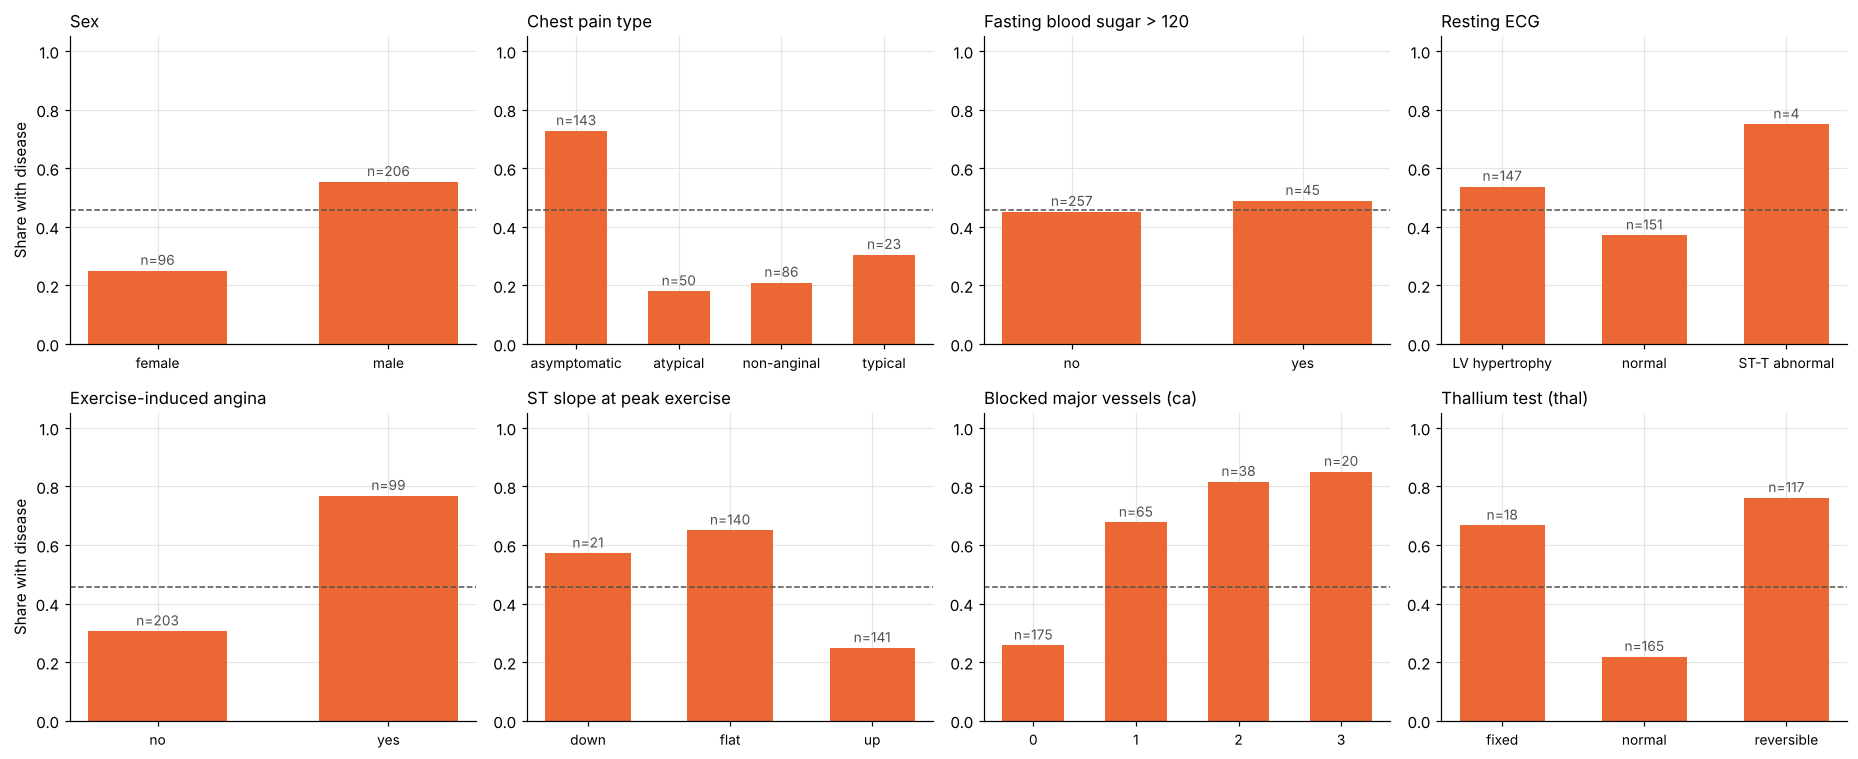

In [11]:
cat_names = {
    "sex":     {0: "female", 1: "male"},
    "cp":      {0: "asymptomatic", 1: "atypical", 2: "non-anginal", 3: "typical"},
    "fbs":     {0: "no", 1: "yes"},
    "restecg": {0: "LV hypertrophy", 1: "normal", 2: "ST-T abnormal"},
    "exang":   {0: "no", 1: "yes"},
    "slope":   {0: "down", 1: "flat", 2: "up"},
    "ca":      {0: "0", 1: "1", 2: "2", 3: "3"},
    "thal":    {1: "fixed", 2: "normal", 3: "reversible"},
}
titles = {"sex": "Sex", "cp": "Chest pain type", "fbs": "Fasting blood sugar > 120",
          "restecg": "Resting ECG", "exang": "Exercise-induced angina",
          "slope": "ST slope at peak exercise", "ca": "Blocked major vessels (ca)",
          "thal": "Thallium test (thal)"}
overall = y.mean()

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.flat, cat_names):
    stats = df.groupby(col)["disease"].agg(["mean", "size"])
    names = [cat_names[col][int(v)] for v in stats.index]
    ax.bar(names, stats["mean"], color=DISEASE, width=0.6)
    for i, (rate, n) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(i, rate + 0.02, f"n={n}", ha="center", fontsize=9, color="#52514e")
    ax.axhline(overall, color="#52514e", linestyle="--", linewidth=1)
    ax.set_ylim(0, 1.05)
    ax.set_title(titles[col], fontsize=11, loc="left")
    ax.tick_params(axis="x", labelsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("Share with disease")
fig.tight_layout()
fig.savefig(FIG_DIR / "categorical_disease_rate.png", dpi=150, bbox_inches="tight")
plt.show()

What the plots show:
- **Chest pain type (`cp`)**: 73% of *asymptomatic* patients have disease, compared with 18–30% of patients who reported chest pain. This looks backwards at first. A likely reason is how patients were selected: everyone in this study was referred for an angiogram, so a patient without chest pain was probably referred because of other worrying results. I note this as a property of this dataset, not as a medical fact.
- **Exercise-induced angina (`exang`)**, **blocked vessels (`ca`)** and a **reversible thallium defect (`thal = 3`)** all come with much higher disease rates.
- **ST slope**: a flat or downsloping slope is linked to disease; upsloping is mostly healthy.
- **Sex**: men in this sample have a much higher rate than women (55% vs 25%). There are only 96 women, so the model will see few female cases.
- **Fasting blood sugar (`fbs`)** makes almost no difference.
- `restecg = 2` has only 4 patients, too few to learn anything from.

## 6. Correlations

Pearson correlation only makes sense for numeric and binary features, so the unordered categorical codes (`cp`, `restecg`, `slope`, `thal`) are left out here; section 5 already covers them. The last row/column is the (flipped) disease label.

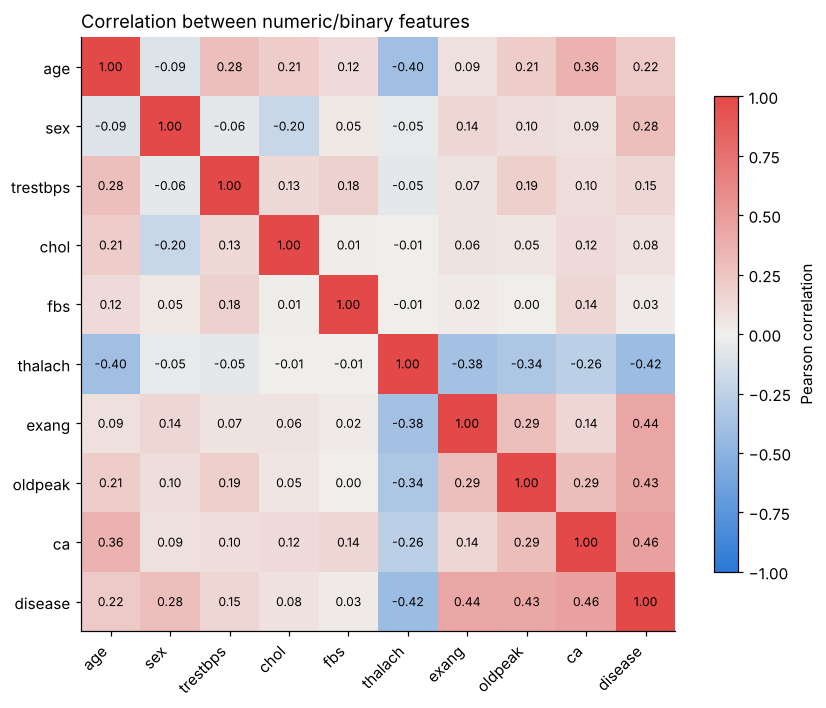

In [12]:
corr_cols = ["age", "sex", "trestbps", "chol", "fbs", "thalach", "exang", "oldpeak", "ca", "disease"]
corr = df[corr_cols].corr()

# Diverging colours: blue (negative) - grey (zero) - red (positive)
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation between numeric/binary features", loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
corr["disease"].drop("disease").sort_values(key=abs, ascending=False).round(2).to_frame("correlation with disease")

,correlation with disease
ca,0.46
exang,0.44
oldpeak,0.43
thalach,-0.42
sex,0.28
age,0.22
trestbps,0.15
chol,0.08
fbs,0.03


- The features most related to disease are `ca`, `exang`, `oldpeak` and `thalach` (all around 0.42–0.46 in absolute value; `thalach` is negative because a lower max heart rate goes with disease).
- `chol` and `fbs` are almost unrelated to the label in this sample.
- No two input features are strongly correlated with each other. The largest is age vs max heart rate at -0.40, which makes sense because max heart rate falls with age. So I do **not** remove features for being redundant. The original notebook's 0.8 correlation filter removed nothing anyway.

## 7. Summary

**Data problems found and fixed (in `src/data.py`):**
1. 723 duplicate rows. Only 302 unique patients. In the old 80/20 split, 199 of 205 test rows were also in the training set, so the old 92.2% test accuracy was inflated.
2. The target label is reversed compared with the original UCI data. Flipped so 1 = disease.
3. `ca = 4` (4 patients) and `thal = 0` (2 patients) are missing values. Set to NaN, filled inside the pipeline.

**What to expect from modelling:**
- 302 patients is a small dataset. One random 80/20 split leaves only about 60 test patients, where one patient changes accuracy by about 1.7 percentage points. That is why we use repeated, stratified cross-validation and report the spread, not a single number.
- Several features carry clear signal (`thalach`, `oldpeak`, `exang`, `ca`, `cp`, `thal`, `slope`), so a simple model like logistic regression should already do reasonably well. Realistic accuracy for this data is probably in the low-to-mid 80s, not 92%.
- `cp`, `restecg`, `slope` and `thal` need one-hot encoding; the numeric features need scaling for logistic regression and SVM. Both must happen inside the pipeline.